# Customer Segmentation with K-Means Clustering

**Goal:** group a shopping mall's customers into segments with similar behaviour, so marketing can target each group with the right offer.

**Dataset:** [Mall Customer Segmentation Data (Kaggle)](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python): 200 customers with gender, age, annual income (k$) and a spending score (1-100) assigned by the mall.

**Workflow:** data checks → EDA → feature selection and scaling → choosing *k* (elbow + silhouette) → K-Means → segment profiling and naming → comparison with other algorithms → stability check → export for the web app.

This is **unsupervised learning**: there is no target column. The model finds structure on its own, and we then interpret what each group means for the business.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src import segmentation as seg

pd.set_option("display.float_format", lambda x: f"{x:.2f}")
sns.set_theme(style="whitegrid")
RANDOM_STATE = seg.RANDOM_STATE
IMG_DIR = ROOT / "images"
IMG_DIR.mkdir(exist_ok=True)

def save_fig(name):
    plt.savefig(IMG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

## 2. Load and check the data

In [2]:
df = seg.load_data()   # renames columns to: customer_id, gender, age, income, spending
print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,customer_id,gender,age,income,spending
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()
print("\nMissing values:", df.isna().sum().sum(), "| Duplicate rows:", df.duplicated().sum(),
      "| Duplicate IDs:", df["customer_id"].duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  200 non-null    int64
 1   gender       200 non-null    str  
 2   age          200 non-null    int64
 3   income       200 non-null    int64
 4   spending     200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Missing values: 0 | Duplicate rows: 0 | Duplicate IDs: 0


,count,mean,std,min,25%,50%,75%,max
customer_id,200.00,100.50,57.88,1.00,50.75,100.50,150.25,200.00
age,200.00,38.85,13.97,18.00,28.75,36.00,49.00,70.00
income,200.00,60.56,26.26,15.00,41.50,61.50,78.00,137.00
spending,200.00,50.20,25.82,1.00,34.75,50.00,73.00,99.00


The data is clean: no missing values and no duplicates. `customer_id` is only an identifier, so it is never used as a feature.

## 3. Exploratory data analysis

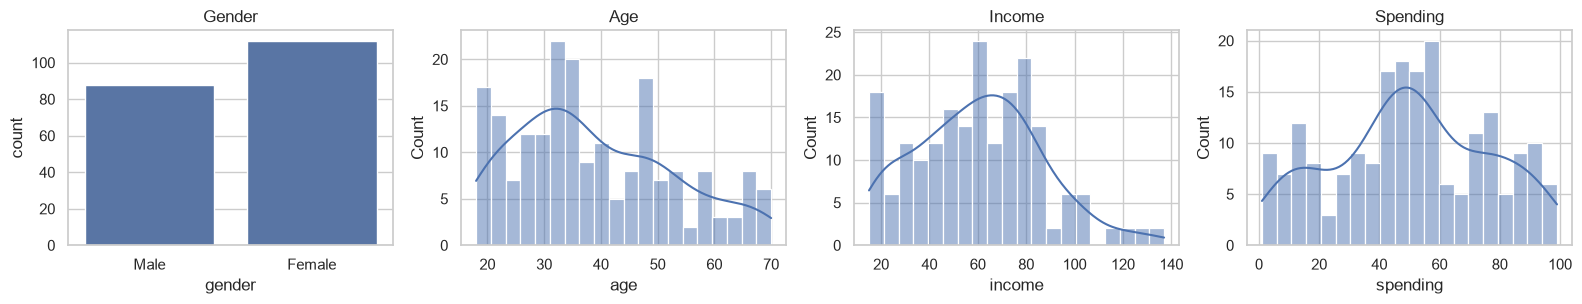

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
sns.countplot(data=df, x="gender", ax=axes[0]); axes[0].set_title("Gender")
for ax, col in zip(axes[1:], ["age", "income", "spending"]):
    sns.histplot(df[col], kde=True, bins=20, ax=ax); ax.set_title(col.capitalize())
plt.tight_layout(); save_fig("distributions"); plt.show()

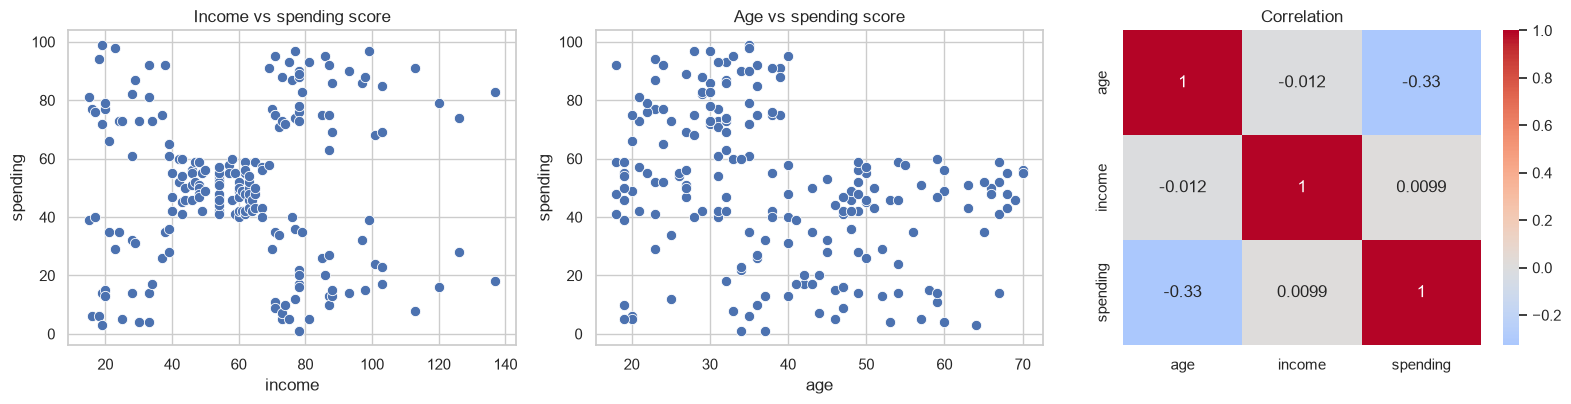

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.scatterplot(data=df, x="income", y="spending", s=55, ax=axes[0])
axes[0].set_title("Income vs spending score")
sns.scatterplot(data=df, x="age", y="spending", s=55, ax=axes[1])
axes[1].set_title("Age vs spending score")
sns.heatmap(df[["age", "income", "spending"]].corr(), annot=True, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Correlation")
plt.tight_layout(); save_fig("eda_relationships"); plt.show()

In [6]:
df.groupby("gender")[["age", "income", "spending"]].mean()

,age,income,spending
gender,,,
Female,38.10,59.25,51.53
Male,39.81,62.23,48.51


**Observations**
- *Income vs spending* shows **five visually distinct groups**: a central cloud plus four corners. This is ideal for K-Means.
- Income and spending are almost uncorrelated (r ≈ 0.01), so each adds independent information.
- Spending falls with age (r ≈ -0.33). None of the 78 customers over 40 scores above 60.
- Gender makes little difference to income or spending, so we exclude it from clustering and use it only for profiling.

## 4. Feature selection and scaling

We cluster on **annual income and spending score**. They are the two behaviours marketing can act on, and two features let us plot the segments directly. Section 8 tests whether adding age helps.

K-Means uses Euclidean distance, so features must be on the same scale. Otherwise the feature with larger numbers dominates. `StandardScaler` converts each to mean 0 and standard deviation 1.

In [7]:
X = df[seg.FEATURES]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pd.DataFrame(X_scaled, columns=seg.FEATURES).describe().loc[["mean", "std"]]

,income,spending
mean,-0.00,-0.00
std,1.00,1.00


## 5. Choosing the number of clusters

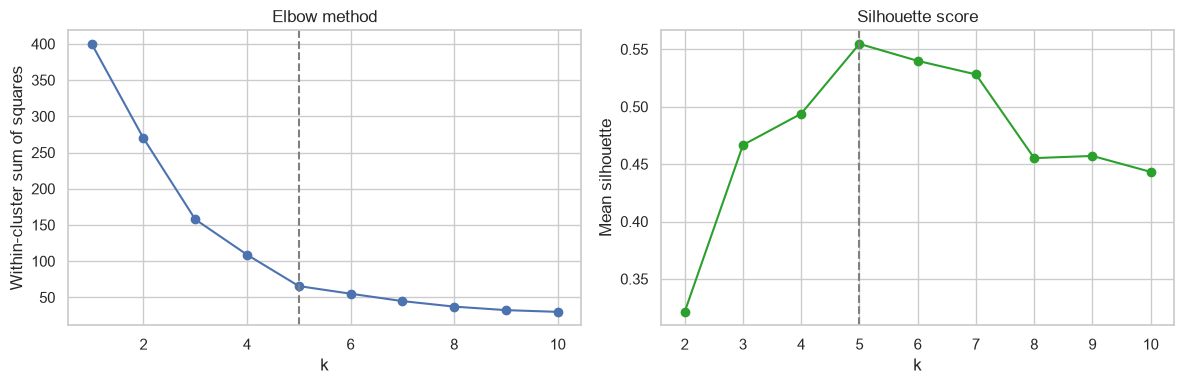

k,2,3,4,5,6,7,8,9,10
silhouette,0.32,0.47,0.49,0.55,0.54,0.53,0.46,0.46,0.44


In [8]:
diag = seg.elbow_and_silhouette(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(diag["k"], diag["wcss"], marker="o")
axes[0].axvline(5, ls="--", c="grey"); axes[0].set_title("Elbow method")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Within-cluster sum of squares")
axes[1].plot(diag["silhouette_k"], diag["silhouette"], marker="o", color="tab:green")
axes[1].axvline(5, ls="--", c="grey"); axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Mean silhouette")
plt.tight_layout(); save_fig("choosing_k"); plt.show()

pd.DataFrame({"k": diag["silhouette_k"], "silhouette": diag["silhouette"]}).set_index("k").T

Both methods agree on **k = 5**:
- **Elbow:** WCSS drops steeply up to k = 5 and flattens after. Extra clusters add little.
- **Silhouette:** k = 5 gives the highest score (≈ 0.55). Points sit clearly closer to their own cluster than to the next one.

## 6. Final K-Means model and segment naming

In [9]:
scaler, kmeans, X_scaled = seg.fit(df, k=5)
df["segment"] = kmeans.labels_
keys = seg.persona_keys(scaler, kmeans)
names = {c: seg.PERSONAS[keys[c]]["name"] for c in range(kmeans.n_clusters)}
df["segment_name"] = df["segment"].map(names)

print("Silhouette:", round(silhouette_score(X_scaled, df["segment"]), 3))
print("Davies-Bouldin (lower is better):", round(davies_bouldin_score(X_scaled, df["segment"]), 3))

Silhouette: 0.555
Davies-Bouldin (lower is better): 0.572


Cluster numbers from K-Means are arbitrary. `persona_keys` names each cluster from the position of its centre (high, low or mid income × high, low or mid spending), so the names stay correct even if the numbering changes.

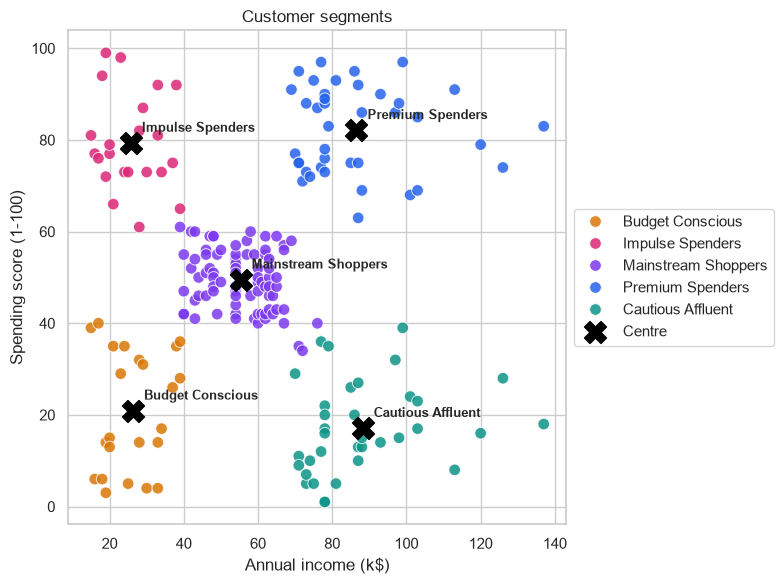

In [10]:
PALETTE = {"Premium Spenders": "#2563eb", "Cautious Affluent": "#0d9488", "Impulse Spenders": "#db2777",
           "Budget Conscious": "#d97706", "Mainstream Shoppers": "#7c3aed"}
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="income", y="spending", hue="segment_name", palette=PALETTE, s=70, alpha=0.85)
plt.scatter(centers[:, 0], centers[:, 1], marker="X", s=250, c="black", label="Centre")
for c, (x, y) in enumerate(centers):
    plt.annotate(names[c], (x, y), xytext=(8, 8), textcoords="offset points", fontsize=9, weight="bold")
plt.xlabel("Annual income (k$)"); plt.ylabel("Spending score (1-100)")
plt.title("Customer segments"); plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); save_fig("segments"); plt.show()

## 7. Segment profiling

In [11]:
profile = (df.groupby("segment_name")
             .agg(customers=("customer_id", "count"),
                  avg_age=("age", "mean"),
                  avg_income=("income", "mean"),
                  avg_spending=("spending", "mean"),
                  female_share=("gender", lambda g: (g == "Female").mean()))
             .sort_values("avg_spending", ascending=False))
profile["share"] = profile["customers"] / len(df)
profile

,customers,avg_age,avg_income,avg_spending,female_share,share
segment_name,,,,,,
Premium Spenders,39,32.69,86.54,82.13,0.54,0.20
Impulse Spenders,22,25.27,25.73,79.36,0.59,0.11
Mainstream Shoppers,81,42.72,55.30,49.52,0.59,0.41
Budget Conscious,23,45.22,26.30,20.91,0.61,0.12
Cautious Affluent,35,41.11,88.20,17.11,0.46,0.17


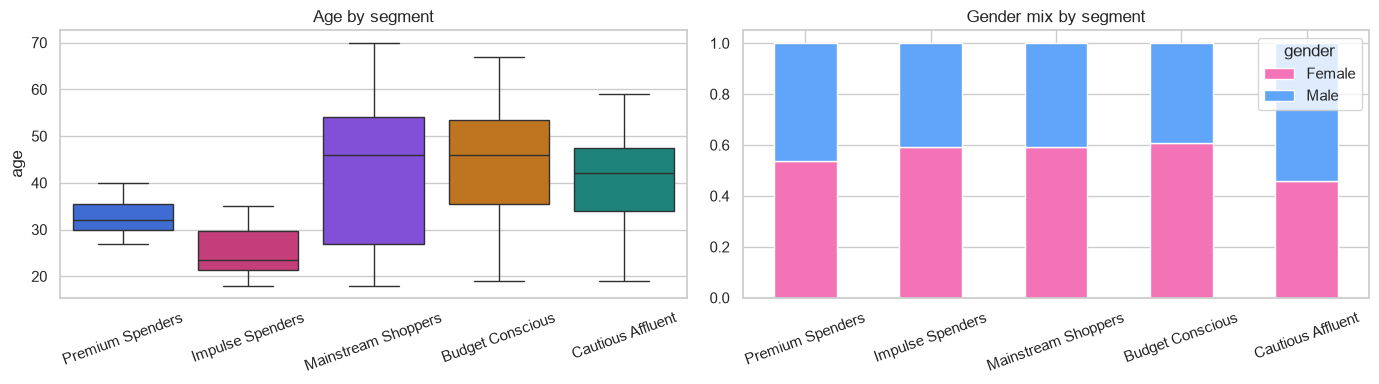

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order = profile.index
sns.boxplot(data=df, x="segment_name", y="age", order=order, palette=PALETTE, hue="segment_name", ax=axes[0])
axes[0].set_title("Age by segment"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=20)
(pd.crosstab(df["segment_name"], df["gender"], normalize="index").loc[order]
   .plot.bar(stacked=True, ax=axes[1], color=["#f472b6", "#60a5fa"]))
axes[1].set_title("Gender mix by segment"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); save_fig("segment_profiles"); plt.show()

In [13]:
for key, p in seg.PERSONAS.items():
    row = profile.loc[p["name"]]
    print(f"■ {p['name']} ({int(row.customers)} customers, {row.share:.0%}), avg age {row.avg_age:.0f}")
    print(f"  {p['description']}")
    for s in p["strategy"]:
        print(f"    - {s}")
    print()

■ Premium Spenders (39 customers, 20%), avg age 33
  The mall's most valuable customers. They earn well and spend freely.
    - VIP loyalty tier with exclusive perks
    - Early access to new collections and events
    - Personal shopping and premium brand partnerships

■ Cautious Affluent (35 customers, 18%), avg age 41
  They can afford to spend but choose not to. This is the biggest untapped opportunity.
    - Quality and value-for-money messaging
    - Personalised offers based on past purchases
    - Survey to understand why they hold back

■ Impulse Spenders (22 customers, 11%), avg age 25
  They spend more than their income suggests and respond strongly to trends.
    - Trend-led campaigns and social media promotions
    - Limited-time and flash offers
    - Student or youth loyalty cards

■ Budget Conscious (23 customers, 12%), avg age 45
  Price-sensitive shoppers who buy mainly essentials.
    - Discounts, bundles and clearance events
    - Highlight affordable stores and ess

**Takeaways**
- **Premium Spenders** (about 20%) are the core revenue group: high income, high spending, average age around 33. Retaining them is the top priority.
- **Cautious Affluent** (about 18%) earn as much as Premium Spenders but spend about a fifth as much, and they are older on average (about 41). They are the largest upside if the mall can convert them.
- **Impulse Spenders** are the youngest group (about 25). Their spending is high relative to income, so they respond well to trends and flash sales.
- **Mainstream Shoppers** are the largest group (about 40%), mostly middle-aged (about 43). They are a stable base for broad campaigns.
- Gender is fairly balanced in every segment, which confirms it does not drive spending behaviour here.

## 8. Comparison with other approaches

In [14]:
rows = []
def evaluate(name, X_, labels):
    mask = labels != -1  # DBSCAN marks noise as -1
    n = len(set(labels[mask]))
    rows.append({"approach": name, "clusters": n, "noise_points": int((~mask).sum()),
                 "silhouette": silhouette_score(X_[mask], labels[mask]) if n > 1 else np.nan,
                 "davies_bouldin": davies_bouldin_score(X_[mask], labels[mask]) if n > 1 else np.nan})

evaluate("K-Means (income, spending)", X_scaled, kmeans.labels_)
evaluate("Agglomerative, Ward (income, spending)", X_scaled,
         AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(X_scaled))
evaluate("DBSCAN eps=0.35 (income, spending)", X_scaled,
         DBSCAN(eps=0.35, min_samples=5).fit_predict(X_scaled))

X3 = StandardScaler().fit_transform(df[["age", "income", "spending"]])
best3 = max(range(2, 11), key=lambda k: silhouette_score(
    X3, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X3)))
evaluate(f"K-Means k={best3} (age, income, spending)", X3,
         KMeans(best3, n_init=10, random_state=RANDOM_STATE).fit_predict(X3))

comparison = pd.DataFrame(rows).set_index("approach")
comparison

,clusters,noise_points,silhouette,davies_bouldin
approach,,,,
"K-Means (income, spending)",5,0,0.55,0.57
"Agglomerative, Ward (income, spending)",5,0,0.55,0.58
"DBSCAN eps=0.35 (income, spending)",6,23,0.56,0.51
"K-Means k=6 (age, income, spending)",6,0,0.43,0.83


In [15]:
agg = AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(X_scaled)
print("Agreement between K-Means and Agglomerative (Adjusted Rand Index):",
      round(adjusted_rand_score(kmeans.labels_, agg), 3))

Agreement between K-Means and Agglomerative (Adjusted Rand Index): 0.942


- **Hierarchical (Ward) clustering** finds almost the same five groups (high Adjusted Rand Index). This independently confirms the segments are real structure and not an artefact of K-Means.
- **DBSCAN** labels the sparse corner customers as noise, which is unhelpful when every customer needs a segment.
- **Adding age** produces more clusters with a lower silhouette. The segments become harder to separate and explain, so the 2-feature model is the better choice for marketing.

## 9. Stability check

In [16]:
seeds = range(20)
labelings = [KMeans(5, n_init=10, random_state=s).fit_predict(X_scaled) for s in seeds]
ari = [adjusted_rand_score(labelings[0], l) for l in labelings[1:]]
print(f"Adjusted Rand Index vs seed 0 across {len(ari)} other seeds: min={min(ari):.3f}, mean={np.mean(ari):.3f}")

Adjusted Rand Index vs seed 0 across 19 other seeds: min=1.000, mean=1.000


Re-running K-Means with 20 different random seeds gives identical segments (ARI = 1.0), so the result does not depend on random initialisation.

## 10. Soft membership: how sure is each assignment?

K-Means gives one hard label per customer. For decisions near a boundary it helps to know **how strongly** a customer belongs to a segment.

**Soft K-Means.** K-Means is the special case of a Gaussian Mixture Model where every cluster is a round bell curve with the *same* variance σ². Taking σ² as the average squared distance of customers to their own centre gives

P(segment k | x) ∝ exp(-d_k² / 2σ²)

where d_k is the scaled distance to centre k. The most likely segment is always the K-Means segment, so the website can show these probabilities next to the hard label without ever contradicting it.

In [17]:
sigma2 = seg.soft_variance(kmeans, X_scaled)
print("Shared variance sigma^2:", round(sigma2, 4))

probs = np.array([seg.segment_probabilities(i, s, scaler, kmeans, sigma2) for i, s in zip(df["income"], df["spending"])])
df["membership_prob"] = probs.max(axis=1)
print("Top-probability segment equals K-Means label for all customers:", (probs.argmax(axis=1) == kmeans.labels_).all())
df.groupby("segment_name")["membership_prob"].describe()[["mean", "min", "50%"]]

Shared variance sigma^2: 0.1639
Top-probability segment equals K-Means label for all customers: True


,mean,min,50%
segment_name,,,
Budget Conscious,0.96,0.56,1.00
Cautious Affluent,0.98,0.68,1.00
Impulse Spenders,0.98,0.63,1.00
Mainstream Shoppers,0.96,0.53,0.99
Premium Spenders,0.99,0.86,1.00


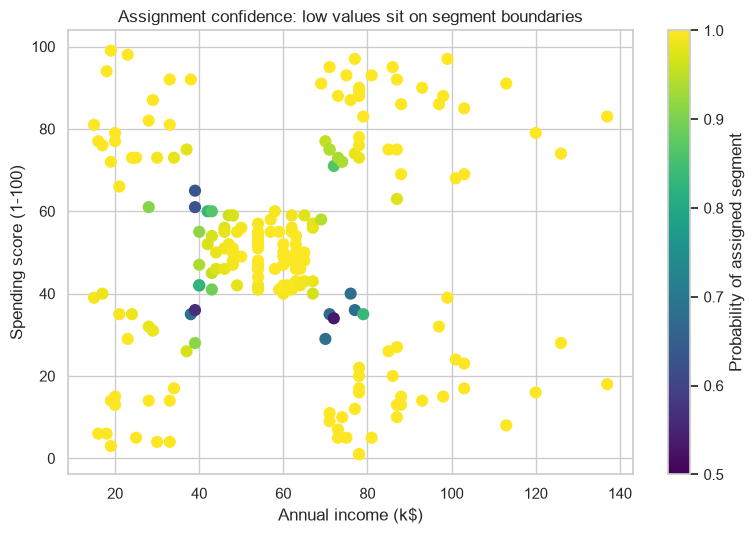

16 of 200 customers (8%) have probability below 90%:


,customer_id,income,spending,segment_name,membership_prob
132,133,72,34,Mainstream Shoppers,0.53
42,43,39,36,Budget Conscious,0.56
43,44,39,61,Mainstream Shoppers,0.63
45,46,39,65,Impulse Spenders,0.63
126,127,71,35,Mainstream Shoppers,0.67
146,147,77,36,Cautious Affluent,0.68
142,143,76,40,Mainstream Shoppers,0.68
124,125,70,29,Cautious Affluent,0.68
40,41,38,35,Budget Conscious,0.69
48,49,40,42,Mainstream Shoppers,0.83


In [18]:
plt.figure(figsize=(8, 5.5))
sc_ = plt.scatter(df["income"], df["spending"], c=df["membership_prob"], cmap="viridis", s=60, vmin=0.5, vmax=1)
plt.colorbar(sc_, label="Probability of assigned segment")
plt.xlabel("Annual income (k$)"); plt.ylabel("Spending score (1-100)")
plt.title("Assignment confidence: low values sit on segment boundaries")
plt.tight_layout(); save_fig("membership_confidence"); plt.show()

borderline = df[df["membership_prob"] < 0.9].sort_values("membership_prob")
print(f"{len(borderline)} of {len(df)} customers ({len(borderline)/len(df):.0%}) have probability below 90%:")
borderline[["customer_id", "income", "spending", "segment_name", "membership_prob"]].head(10)

Most customers are assigned with near-certainty. Every borderline customer sits on the edge of the Mainstream segment, most often next to Cautious Affluent (6) or Budget Conscious (5). They are good candidates for a mixed campaign, or for watching to see which way they move.

**Cross-check with a full Gaussian Mixture Model.** A GMM lets every cluster have its own shape and size. If it largely agrees with K-Means, the segments are not an artefact of K-Means' round-cluster assumption.

In [19]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=5, covariance_type="full", means_init=kmeans.cluster_centers_,
                      random_state=RANDOM_STATE).fit(X_scaled)
gmm_labels = gmm.predict(X_scaled)
print("GMM vs K-Means agreement on customers:", f"{(gmm_labels == kmeans.labels_).mean():.1%}")
print("Adjusted Rand Index:", round(adjusted_rand_score(kmeans.labels_, gmm_labels), 3))
df[gmm_labels != kmeans.labels_][["customer_id", "income", "spending", "segment_name"]]

GMM vs K-Means agreement on customers: 98.5%
Adjusted Rand Index: 0.956


,customer_id,income,spending,segment_name
45,46,39,65,Impulse Spenders
146,147,77,36,Cautious Affluent
160,161,79,35,Cautious Affluent


The full GMM agrees with K-Means on about 98% of customers, and the few disagreements are all boundary customers. The website uses soft K-Means rather than the full GMM because the GMM's differently sized clusters can claim areas far from any data, so its top segment would sometimes contradict the K-Means segment shown to users.

## 11. Assign new customers and export for the web app

In [20]:
for income, spending in [(20, 85), (90, 15), (60, 55), (95, 90), (25, 10)]:
    c = seg.predict_segment(income, spending, scaler, kmeans)
    print(f"income {income:>3}k, spending {spending:>3}  →  {names[c]}")

income  20k, spending  85  →  Impulse Spenders
income  90k, spending  15  →  Cautious Affluent
income  60k, spending  55  →  Mainstream Shoppers
income  95k, spending  90  →  Premium Spenders
income  25k, spending  10  →  Budget Conscious


In [21]:
# writes models/kmeans.joblib and docs/data/model.json (used by the website in docs/)
seg.main()

Silhouette score: 0.5547
  cluster 0: Mainstream Shoppers  n=81  income= 55.3  spending= 49.5
  cluster 1: Premium Spenders     n=39  income= 86.5  spending= 82.1
  cluster 2: Impulse Spenders     n=22  income= 25.7  spending= 79.4
  cluster 3: Cautious Affluent    n=35  income= 88.2  spending= 17.1
  cluster 4: Budget Conscious     n=23  income= 26.3  spending= 20.9
Wrote docs/data/model.json and docs/data/model.js


## 12. Conclusions

- K-Means with **k = 5** on scaled income and spending gives well-separated segments (**silhouette ≈ 0.55**). The elbow method, the silhouette score and hierarchical clustering all agree, and the result is stable across random seeds.
- Each segment maps to a clear persona with its own marketing action: retain **Premium Spenders**, convert **Cautious Affluent**, engage **Impulse Spenders** with trends, use value offers for **Budget Conscious**, and keep **Mainstream Shoppers** loyal.
- New customers can be assigned instantly with the nearest-centre rule, and soft K-Means adds a membership probability that flags borderline customers. A full Gaussian Mixture Model agrees on about 98% of customers.
- The website in `docs/` runs all of this in the browser: single-customer lookup with probabilities, batch CSV scoring, and a live k explorer.

**Limitations**
- Only 200 customers and 4 attributes. The spending score is a mall-defined index with an unpublished formula.
- K-Means assumes round, similar-sized clusters. That fits here but may not on richer data.
- Segments are a snapshot. In production they should be refreshed regularly from transaction data.

**Future work:** add purchase frequency and recency (RFM features), and track how customers move between segments over time.